In [2]:
%pip install numpy==1.26.4
%pip install pgmpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
label-studio 1.20.0 requires numpy<2.0.0,>=1.26.4, but you have numpy 2.4.6 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Первичный анализ данных

**Что значат переменные, которые вошли в модель:**

| Переменная | Смысл |
|---|---|
| `dataset` | клиника, где собраны данные | 
| `age` | возраст | 
| `sex` | пол | 
| `cp` | тип боли в груди |
| `thalch` | максимальный пульс на пробе | 
| `exang` | стенокардия, вызванная нагрузкой |
| `oldpeak` | депрессия сегмента ST на нагрузке | 
| `target` | болезнь сердца: `num>0` |

In [1]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork as BN
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination
from scipy.stats import chi2_contingency
import networkx as nx

In [2]:
df = pd.read_csv("heart_disease_uci.csv")
display(df.shape)
display(df.head())
display(df.dtypes)
print("Пациенты по клиникам:")
display(df.dataset.value_counts())

display(f"Полных дубликатов: {df.duplicated().sum()}")
display(f"Распределение таргета num: ", df.num.value_counts().sort_index())

(920, 16)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


id            int64
age           int64
sex          object
dataset      object
cp           object
trestbps    float64
chol        float64
fbs          object
restecg      object
thalch      float64
exang        object
oldpeak     float64
slope        object
ca          float64
thal         object
num           int64
dtype: object

Пациенты по клиникам:


dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

'Полных дубликатов: 0'

'Распределение таргета num: '

num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

**Вывод** 920 уникальных пациентов и 16 признаков, среди которых есть как числовые, так и категориальные. `num` принимает значение от 0 до 4, но по факту значения от 1 до 4 - человек болен. То есть распределение примерно равное так как в num = 0 - 411 пациентов, а в num = 1, 2, 3 - 509.

In [3]:
print("chol = 0 по клиникам: ")
display((df.chol == 0).groupby(df.dataset).sum())
print('oldpeak < 0:', (df.oldpeak < 0).sum(), '| по клиникам:', df.loc[df.oldpeak < 0, 'dataset'].value_counts())

print("trestbps = 0 по клиникам")
display((df.trestbps == 0).groupby(df.dataset).sum())

df["chol"] = df["chol"].replace(0, np.nan)
df["trestbps"] = df["trestbps"].replace(0, np.nan)

chol = 0 по клиникам: 


dataset
Cleveland          0
Hungary            0
Switzerland      123
VA Long Beach     49
Name: chol, dtype: int64

oldpeak < 0: 12 | по клиникам: dataset
Switzerland      11
VA Long Beach     1
Name: count, dtype: int64
trestbps = 0 по клиникам


dataset
Cleveland        0
Hungary          0
Switzerland      0
VA Long Beach    1
Name: trestbps, dtype: int64

**Что видно:** нули в `chol` — это не измерения, а замена пропусков (Switzerland: все 123 строки). Отрицательный `oldpeak` (12 строк) почти целиком из Switzerland.

dataset   Cleveland  Hungary  Switzerland  VA Long Beach  кол-во пропусков
age               0        0            0              0                 0
sex               0        0            0              0                 0
dataset           0        0            0              0                 0
cp                0        0            0              0                 0
trestbps          0        0            1             28                 6
chol              0        7          100             28                21
fbs               0        2           60              3                 9
restecg           0        0            0              0                 0
thalch            0        0            0             26                 5
exang             0        0            0             26                 5
oldpeak           0        0            4             28                 6
slope             0       64           13             51                33
ca                1      

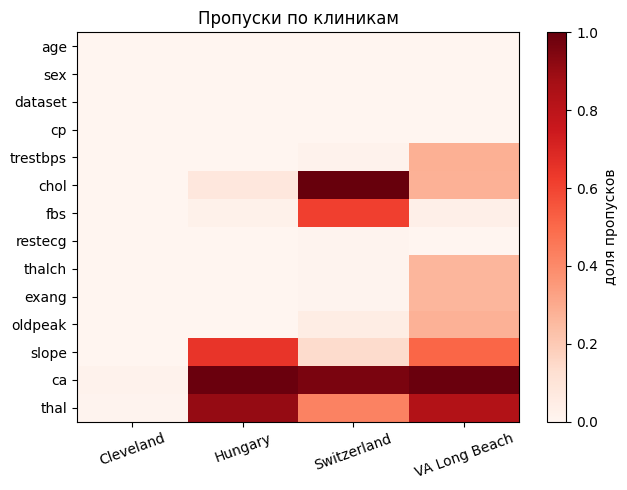

In [5]:
cols = [c for c in df.columns if c not in ["id", "num"]]
miss = df[cols].isna().groupby(df.dataset).mean().T
miss["кол-во пропусков"] = df[cols].isna().mean()
print((100 * miss).round(2).astype(int))

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(miss.iloc[:, :4], cmap='Reds', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(4)); ax.set_xticklabels(miss.columns[:4], rotation=20)
ax.set_yticks(range(len(miss))); ax.set_yticklabels(miss.index)
plt.colorbar(im, label='доля пропусков'); plt.title('Пропуски по клиникам'); plt.tight_layout(); plt.show()

                 n  доля_больных
dataset                         
Cleveland      304         0.457
Hungary        293         0.362
Switzerland    123         0.935
VA Long Beach  200         0.745 

Общая доля больных: 0.553 

           age  thalch  oldpeak
disease                        
0        50.55  148.80     0.42
1        55.90  128.26     1.26


disease     0     1
exang              
False    0.64  0.36
True     0.16  0.84


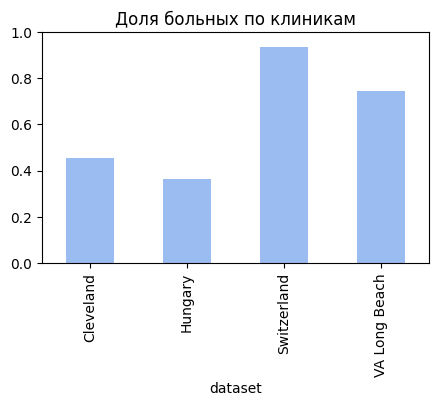

In [6]:
df["disease"] = (df.num > 0).astype(int)
prev = df.groupby('dataset').disease.agg(n='size', доля_больных='mean').round(3)
print(prev, '\n')
print("Общая доля больных:", df.disease.mean().round(3), "\n")
print(df.groupby("disease")[["age", "thalch", "oldpeak"]].mean().round(2))
print("\n")
print(pd.crosstab(df.exang, df.disease, normalize="index").round(2))

prev['доля_больных'].plot.bar(figsize=(5, 3), color='#9bbcf0', title='Доля больных по клиникам'); plt.ylim(0, 1); plt.show()

**Что видно:** **доля больных резко различается между клиниками**: Hungary 0.36, Cleveland 0.46, VA 0.75, Switzerland 0.93 — это разные популяции и/или правила направления на обследование. Поэтому `dataset` обязательно нужен модели (иначе клиника станет скрытым общим фактором). Метки корректны: у больных выше возраст (55.9 против 50.5), ниже пульс (128 против 149), выше `oldpeak` (1.3 против 0.4), а при `exang=True` доля больных 0.84 против 0.36.

In [8]:
def binned(s):
    return pd.qcut(s, 3, duplicates='drop') if s.dtype.kind in 'if' and s.nunique() > 6 else s.astype(str)
rows = []
for c in ['dataset', 'age', 'sex', 'cp', 'thalch', 'exang', 'oldpeak', 'trestbps', 'fbs', 'restecg', 'slope', 'ca', 'thal', 'chol']:
    x = df[[c, 'disease']].dropna()
    p = chi2_contingency(pd.crosstab(binned(x[c]), x.disease))[1]
    rows.append((c, df[c].isna().sum(), round(100 * df[c].isna().mean()), round(p, 4)))
scr = pd.DataFrame(rows, columns=['признак', 'пропусков', '% пропусков', 'p-value (связь с target)'])
scr['в модели'] = scr['признак'].isin(['dataset', 'age', 'sex', 'cp', 'thalch', 'exang', 'oldpeak'])
print(scr.to_string(index=False))
print('\nchol и болезнь внутри клиник (порог 240, где chol известен):')
for s, g in df[df.chol.notna()].groupby('dataset'):
    print(f'  {s:14s} n={len(g):3d}  p = {chi2_contingency(pd.crosstab(g.chol >= 240, g.disease))[1]:.3f}')

 признак  пропусков  % пропусков  p-value (связь с target)  в модели
 dataset          0            0                    0.0000      True
     age          0            0                    0.0000      True
     sex          0            0                    0.0000      True
      cp          0            0                    0.0000      True
  thalch         55            6                    0.0000      True
   exang         55            6                    0.0000      True
 oldpeak         62            7                    0.0000      True
trestbps         60            7                    0.0001     False
     fbs         90           10                    0.0001     False
 restecg          2            0                    0.0029     False
   slope        309           34                    0.0000     False
      ca        611           66                    0.0000     False
    thal        486           53                    0.0000     False
    chol        202           22  

**Что видно:** все признаки связаны с болезнью (p ≤ 0.01), так что отбор идёт не по силе связи, а по **пригодности**: в модель взяты признаки без массовых пропусков (`dataset, age, sex, cp, thalch, exang, oldpeak`). Исключены `ca`, `thal`, `slope` (34-66% пропусков, привязанных к клиникам), `fbs`, `trestbps`, `restecg` (специфические измерения, меньше смысла для графа) и `chol` (22% непригодных значений). Это **потеря информации**, особенно по `ca` и `thal`, которые сильные предикторы, но их нельзя использовать без выбрасывания целых клиник. Внутри клиник холестерин связан с болезнью слабее, чем в целом (Cleveland p=0.06, Hungary p=0.022, VA p=0.418), то есть часть общего эффекта — разница между клиниками.

In [11]:
use = ["dataset", "age", "sex", "cp", "thalch", "exang", "oldpeak"]
data = df.dropna(subset=use).reset_index(drop=True)
cmp_ = pd.DataFrame({"n до": df.groupby("dataset").size(), "n после": data.groupby("dataset").size(),
                     'доля больных до': df.groupby('dataset').disease.mean().round(3),
                                          'доля больных после': data.groupby('dataset').disease.mean().round(3)})

print(cmp_.to_string()); print('Всего:', len(df), '->', len(data), '| доля больных', round(df.disease.mean(), 3), '->', round(data.disease.mean(), 3))
print('\nПропуски thalch / exang / oldpeak по строкам (True = пропуск):')
display(df[['thalch', 'exang', 'oldpeak']].isna().value_counts())


               n до  n после  доля больных до  доля больных после
dataset                                                          
Cleveland       304      304            0.457               0.457
Hungary         293      292            0.362               0.363
Switzerland     123      117            0.935               0.932
VA Long Beach   200      144            0.745               0.792
Всего: 920 -> 857 | доля больных 0.553 -> 0.546

Пропуски thalch / exang / oldpeak по строкам (True = пропуск):


thalch  exang  oldpeak
False   False  False      857
True    True   True        54
False   False  True         8
True    True   False        1
Name: count, dtype: int64

**Что видно:** удалено 63 строки (6.8%), из них 56 — VA. Пропуски `thalch` и `exang` совпадают построчно (у этих пациентов, вероятно, не проводили нагрузочную пробу). Общая доля больных почти не изменилась (0.553 → 0.546), но в VA выросла (0.745 → 0.792): удалены пациенты без пробы, среди которых больных было меньше. Дальше работаем с N = 857.

         age  thalch  oldpeak
count  857.0   857.0    857.0
mean    53.1   137.6      0.9
std      9.4    25.8      1.1
min     28.0    60.0     -2.6
25%     46.0   120.0      0.0
33.3%   50.0   125.0      0.0
50%     54.0   140.0      0.5
66.7%   58.0   150.0      1.2
75%     60.0   157.0      1.5
max     77.0   202.0      6.2

oldpeak <= 0: 382 (45%), из них < 0: 12


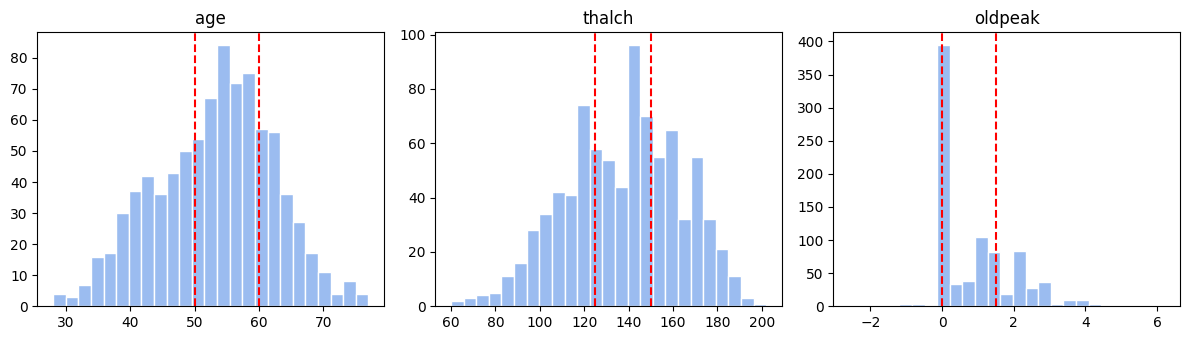

Границы тертилей пульса: [125.0, 150.0]
age
(0, 50]      309
(50, 60]     357
(60, 100]    191
Name: count, dtype: int64
thalch
(0, 125]      292
(125, 150]    290
(150, 250]    275
Name: count, dtype: int64


In [13]:
print(data[['age', 'thalch', 'oldpeak']].describe(percentiles=[.25, 1/3, .5, 2/3, .75]).round(1))
print('\noldpeak <= 0: %d (%.0f%%), из них < 0: %d' % ((data.oldpeak <= 0).sum(), 100 * (data.oldpeak <= 0).mean(), (data.oldpeak < 0).sum()))
t_cuts = data.thalch.quantile([1/3, 2/3]).round(0).tolist()
cuts = {'age': [50, 60], 'thalch': t_cuts, 'oldpeak': [0, 1.5]}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, c in zip(axes, cuts):
    ax.hist(data[c], bins=25, color='#9bbcf0', edgecolor='white')
    for x in cuts[c]: ax.axvline(x, color='red', ls='--')
    ax.set_title(c)
plt.tight_layout(); plt.show()
print('Границы тертилей пульса:', t_cuts)

d = df.dropna(subset=['thalch', 'exang', 'oldpeak'])  

print(pd.cut(d['age'],    bins=[0, 50, 60, 100]).value_counts().sort_index())
print(pd.cut(d['thalch'], bins=[0, 125, 150, 250]).value_counts().sort_index())

**Что видно:** возраст 28-77, квартили 46 / 54 / 60, границы 50 и 60 дают группы 309 / 357 / 191. Пульс распределён широко (60-202), тертили 125 и 150 дают три почти равные группы (292 / 290 / 275). У `oldpeak` пик в нуле: ≤0 у 45% пациентов, поэтому ноль выделен отдельным состоянием, а порог 1.5 отделяет умеренную депрессию ST от выраженной.

In [15]:
df = pd.DataFrame({
    'dataset': data.dataset.map({'Cleveland': 'Cleveland', 'Hungary': 'Hungary', 'Switzerland': 'Switzerland', 'VA Long Beach': 'VA'}),
    'age':     pd.cut(data.age, [0, 50, 60, 120], labels=['<=50', '51-60', '>60']).astype(str),
    'sex':     data.sex.map({'Female': 'F', 'Male': 'M'}),
    'cp':      data.cp.map({'typical angina': 'typical', 'atypical angina': 'atypical',
                            'non-anginal': 'nonanginal', 'asymptomatic': 'asympt'}),
    'thalch':  pd.qcut(data.thalch, 3, labels=['low', 'mid', 'high']).astype(str),
    'exang':   data.exang.map({False: 'no', True: 'yes'}),
    'oldpeak': pd.cut(data.oldpeak, [-10, 0, 1.5, 10], labels=['<=0', '0-1.5', '>1.5']).astype(str),
    'target':  np.where(data.num > 0, 'yes', 'no')})

assert not df.isna().any().any() and not (df == 'nan').any().any()      
for c in df:
    print(f'{c:8s}', df[c].value_counts().to_dict())
print('\nСамое маленькое состояние:', min(df[c].value_counts().min() for c in df), 'пациентов')

dataset  {'Cleveland': 304, 'Hungary': 292, 'VA': 144, 'Switzerland': 117}
age      {'51-60': 357, '<=50': 309, '>60': 191}
sex      {'M': 665, 'F': 192}
cp       {'asympt': 465, 'nonanginal': 185, 'atypical': 166, 'typical': 41}
thalch   {'low': 292, 'mid': 290, 'high': 275}
exang    {'no': 524, 'yes': 333}
oldpeak  {'<=0': 382, '0-1.5': 267, '>1.5': 208}
target   {'yes': 468, 'no': 389}

Самое маленькое состояние: 41 пациентов


**Что видно:** нет пропусков, 8 переменных, не более 4 состояний у каждой, все состояния содержат не менее 41 пациента; классы `target` почти сбалансированы (468 / 389).

## Вопросы к модели
1. **Симптомы.** Как меняется вероятность болезни, если известно, что при нагрузке возникает стенокардия (`exang=yes`), или тип боли `asympt`?
2. **Демография и клиника.** Как различается вероятность болезни у пожилого мужчины и молодой женщины и как она зависит от клиники, где проходит обследование?
3. **Пульс.** Как возраст и диагноз влияют на максимальный пульс `thalch`: что объясняет низкий пульс у пожилых — возраст или болезнь?

### Структура сети

In [17]:
def p_marg(a, b):
    return chi2_contingency(pd.crosstab(df[a], df[b]))[1]
def p_cond(a, b, c):                      
    return {k: round(float(chi2_contingency(pd.crosstab(g[a], g[b]))[1]), 4) for k, g in df.groupby(c)}
def mi(a, b, cond=None):                   
    def _mi(x):
        t = pd.crosstab(x[a], x[b]).values / len(x); pa = t.sum(1, keepdims=True); pb = t.sum(0, keepdims=True)
        with np.errstate(all='ignore'):
            return np.nansum(t * np.log(t / (pa * pb)))
    return _mi(df) if cond is None else sum(len(g) / len(df) * _mi(g) for _, g in df.groupby(cond))

print('Связь с target (взаимная информация):')
for x in ['cp', 'exang', 'dataset', 'oldpeak', 'thalch', 'sex', 'age']:
    print(f'  {x:8s} MI = {mi(x, "target"):.3f}   p = {p_marg(x, "target"):.4f}')

print('\nОстаточные зависимости при известном target (CMI; p по классам target no / yes):')
pairs = [('dataset','thalch'), ('dataset','oldpeak'), ('exang','oldpeak'), ('cp','exang'), ('dataset','cp'),
         ('exang','thalch'), ('age','oldpeak'), ('cp','oldpeak'), ('age','thalch'), ('cp','thalch'),
         ('thalch','oldpeak'), ('dataset','exang'), ('sex','thalch'), ('age','cp'), ('age','exang')]
for a, b in pairs:
    print(f'  {a:8s}-{b:8s} CMI = {mi(a, b, "target"):.3f}   p:', p_cond(a, b, 'target'))
print('\nКлиника и состав пациентов:')
print(pd.crosstab(df.dataset, df.age, normalize='index').round(2).to_string()); print(pd.crosstab(df.dataset, df.sex, normalize='index').round(2).to_string())

Связь с target (взаимная информация):
  cp       MI = 0.160   p = 0.0000
  exang    MI = 0.114   p = 0.0000
  dataset  MI = 0.101   p = 0.0000
  oldpeak  MI = 0.081   p = 0.0000
  thalch   MI = 0.077   p = 0.0000
  sex      MI = 0.048   p = 0.0000
  age      MI = 0.035   p = 0.0000

Остаточные зависимости при известном target (CMI; p по классам target no / yes):
  dataset -thalch   CMI = 0.073   p: {'no': 0.0, 'yes': 0.0}
  dataset -oldpeak  CMI = 0.056   p: {'no': 0.0, 'yes': 0.0001}
  exang   -oldpeak  CMI = 0.040   p: {'no': 0.0, 'yes': 0.0}
  cp      -exang    CMI = 0.042   p: {'no': 0.0, 'yes': 0.0}
  dataset -cp       CMI = 0.037   p: {'no': 0.0, 'yes': 0.5399}
  exang   -thalch   CMI = 0.035   p: {'no': 0.0152, 'yes': 0.0}
  age     -oldpeak  CMI = 0.032   p: {'no': 0.0, 'yes': 0.1019}
  cp      -oldpeak  CMI = 0.031   p: {'no': 0.0, 'yes': 0.097}
  age     -thalch   CMI = 0.024   p: {'no': 0.0002, 'yes': 0.0007}
  cp      -thalch   CMI = 0.021   p: {'no': 0.0011, 'yes': 0.0147}

$MI = \sum_{x, y} p(x, y) \log_2 \frac{p(x, y)}{p(x)p(y)}$ - сколько информации несет признак X о целевом значении target (в натах, где 1 нат ~ 1.443 бита)

**Что видно.** Все связи с `target` значимы; самые сильные по информации — `cp` (0.160), `exang` (0.114), `dataset` (0.101). После фиксации `target` остаются зависимости: самые заметные — `dataset–thalch` (CMI 0.073) и `dataset–oldpeak` (0.056), то есть **клиники различаются в измерениях при одинаковом диагнозе** (протокол пробы, состав пациентов). Остальные остаточные связи слабее (≤0.042): `cp–exang`, `dataset–cp`, `exang–thalch`, `age–oldpeak`, `cp–oldpeak`. Состав пациентов зависит от клиники: в Hungary 59% моложе 51 года и 3% старше 60, в VA 46% старше 60; женщин в VA 3%, в Switzerland 9%.

**Правило выбора рёбер.** Ребро добавляется, если есть содержательное объяснение направления; остаточная зависимость при известном `target` с CMI > 0.05 — дополнительный довод. Рёбра с меньшей силой, для которых нет очевидного направления (`cp–exang`: оба — проявления стенокардии), намеренно не добавлены, чтобы граф оставался читаемым, а CPT не разрастались; это упрощение указано в ограничениях.

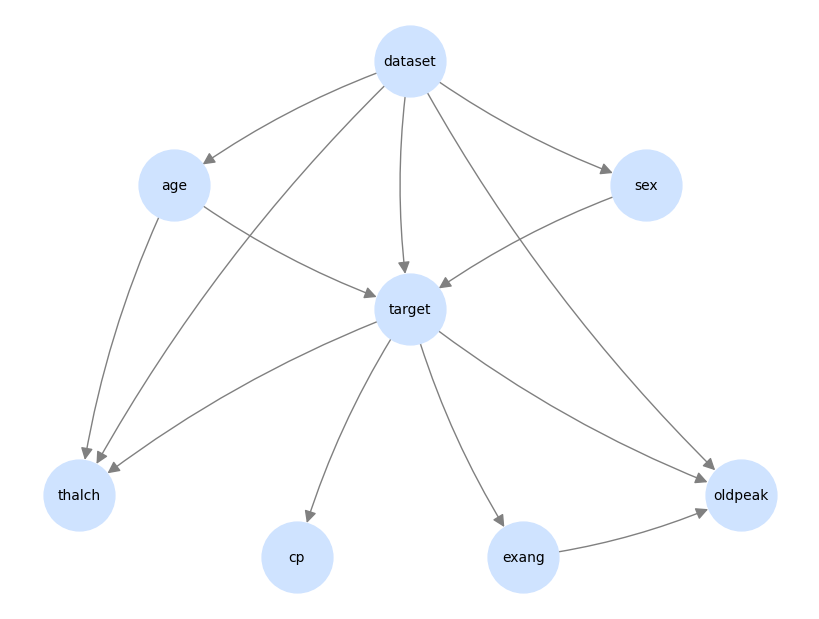

In [20]:
edges = [('dataset','age'), ('dataset','sex'), ('dataset','target'), ('age','target'), ('sex','target'),
         ('age','thalch'), ('dataset','thalch'), ('target','thalch'), ('target','cp'), ('target','exang'),
         ('target','oldpeak'), ('exang','oldpeak'), ('dataset','oldpeak')]

def build(edges):
    m = BN(edges)     
    est = BayesianEstimator(m, df)
    cpds = [est.estimate_cpd(node, prior_type='dirichlet', pseudo_counts=1) for node in m.nodes()]
    m.add_cpds(*cpds)
    assert m.check_model()
    return m

model = build(edges)

pos = {'dataset': (0, 3), 'age': (-2.5, 2), 'sex': (2.5, 2), 'target': (0, 1),
       'thalch': (-3.5, -0.5), 'cp': (-1.2, -1), 'exang': (1.2, -1), 'oldpeak': (3.5, -0.5)}
plt.figure(figsize=(8, 6))
nx.draw(nx.DiGraph(model.edges()), pos, with_labels=True, node_color='#cfe3ff', node_size=2600,
        font_size=10, arrowsize=18, edge_color='gray', connectionstyle='arc3,rad=0.08')
plt.show()

### Граф и обоснование рёбер

| Ребро | Почему зависимость | Почему такое направление |
|---|---|---|
| `dataset → age`, `dataset → sex` | клиники набирают разных пациентов: VA — в основном пожилые мужчины (97% мужчин), Hungary — моложе | клиника — контекст выборки и определяет, какие пациенты в неё попали; возраст и пол пациента клинику «не создают» (направление условное) |
| `dataset → target` | доля больных различается от 36% до 93% (правила направления, популяция) | контекст выборки влияет на долю больных, обратное бессмысленно |
| `age → target`, `sex → target` | риск растёт с возрастом, у мужчин выше (доля больных M 0.63, F 0.26) | возраст и пол — внешние признаки, могут быть только причинами |
| `age → thalch` | максимальный пульс физиологически снижается с возрастом | возраст влияет на пульс, не наоборот |
| `target → thalch` | при болезни сердца пульс на нагрузке ограничен | болезнь проявляется в пробе |
| `dataset → thalch` | остаточная связь при известном диагнозе (CMI 0.073) — различия протоколов и популяций | клиника задаёт условия измерения |
| `target → cp`, `target → exang`, `target → oldpeak` | симптомы и ЭКГ-показатели — проявления болезни | признак отражает состояние сердца, поэтому стрелка от диагноза |
| `exang → oldpeak` | ST-депрессия на нагрузке отражает ту же ишемию, что и приступ (зависимость остаётся при известном `target`) | приступ — событие, ST-депрессия — его регистрируемый след (направление условное, раздел 7) |
| `dataset → oldpeak` | остаточная связь (CMI 0.056); например, у здоровых без стенокардии `oldpeak ≤ 0` в Hungary у 89%, в Cleveland у 46% | клиника задаёт протокол регистрации |

Граф ацикличен (`BN(edges)` бросит ошибку при цикле), 13 рёбер, листья — `cp`, `thalch`, `oldpeak`.

### Условные вероятности

In [21]:
for v in ['dataset', 'age', 'sex', 'cp', 'exang', 'target']:
    print(model.get_cpds(v))

+----------------------+----------+
| dataset(Cleveland)   | 0.354239 |
+----------------------+----------+
| dataset(Hungary)     | 0.340302 |
+----------------------+----------+
| dataset(Switzerland) | 0.13705  |
+----------------------+----------+
| dataset(VA)          | 0.168409 |
+----------------------+----------+
+------------+---------------------+-----+---------------------+
| dataset    | dataset(Cleveland)  | ... | dataset(VA)         |
+------------+---------------------+-----+---------------------+
| age(51-60) | 0.42671009771986973 | ... | 0.42857142857142855 |
+------------+---------------------+-----+---------------------+
| age(<=50)  | 0.3127035830618892  | ... | 0.11564625850340136 |
+------------+---------------------+-----+---------------------+
| age(>60)   | 0.26058631921824105 | ... | 0.4557823129251701  |
+------------+---------------------+-----+---------------------+
+---------+--------------------+-----+--------------------+
| dataset | dataset(Cleveland) 

In [22]:
infer = VariableElimination(model)

def q(var, evidence=None, inf=infer):
    r = inf.query([var], evidence=evidence or {}, show_progress=False)
    return dict(zip(r.state_names[var], r.values.round(3).tolist()))

chk = df.groupby(['dataset', 'age', 'sex']).target.agg(n='size', доля_сырая=lambda s: round((s == 'yes').mean(), 2))
chk['модель'] = [q('target', {'dataset': d, 'age': a, 'sex': s})['yes'] for d, a, s in chk.index]
print(chk.to_string())

                         n  доля_сырая  модель
dataset     age   sex                         
Cleveland   51-60 F     36        0.33   0.342
                  M     94        0.57   0.573
            <=50  F     27        0.04   0.069
                  M     68        0.41   0.414
            >60   F     34        0.35   0.361
                  M     45        0.71   0.702
Hungary     51-60 F     30        0.17   0.188
                  M     82        0.48   0.476
            <=50  F     48        0.15   0.160
                  M    123        0.41   0.408
            >60   F      2        0.00   0.250
                  M      7        0.71   0.667
Switzerland 51-60 F      1        1.00   0.667
                  M     52        0.92   0.907
            <=50  F      3        1.00   0.800
                  M     24        0.92   0.885
            >60   F      6        1.00   0.875
                  M     31        0.94   0.909
VA          51-60 F      3        0.67   0.600
             

**Разбор самых интересных таблиц** (в `P(target | …)` указана вероятность болезни):

* **`P(target | dataset, age, sex)`** — главная таблица. При одинаковых демографических характеристиках клиника сильно меняет вероятность: для мужчин 51-60 лет Hungary 0.48, Cleveland 0.57, VA 0.77, Switzerland 0.91 (сырые доли 0.48 / 0.57 / 0.78 / 0.92). Возраст и пол работают в ожидаемую сторону: в Cleveland у мужчин ≤50 лет 0.41, 51-60 — 0.57, >60 — 0.70; у женщин ≤50 лет 0.07. Модель хорошо согласуется с сырыми долями в больших ячейках.
* **Необычный результат: разреженные ячейки.** Для женщин из Switzerland ≤50 лет (3 пациента, все больные, сырая доля 1.0) модель даёт 0.875, для 51-60 (1 пациент) — 0.67: сглаживание тянет редкие ячейки к середине. Для Hungary >60 лет у женщин (2 пациента, 0 больных) модель даёт 0.25. Такие значения нельзя интерпретировать как реальные риски.
* **`P(age | dataset)`, `P(sex | dataset)`:** Hungary — самая молодая клиника (58% моложе 51 года, лишь 3% старше 60), VA — самая возрастная (46% старше 60) и почти полностью мужская (96%). Часть различий в вероятности болезни между клиниками, таким образом, объясняется составом пациентов, но не вся: внутри одной демографической группы различия остаются (см. выше).
* **`P(cp | target)`: необычный результат.** При болезни `asympt` встречается у 78% пациентов, `typical` лишь у 4%; у здоровых распределение ровнее (asympt 25%, atypical 37%, nonanginal 32%). То есть «боли нет» — самый сильный признак болезни, а типичная стенокардия среди больных редка. Объяснения-гипотезы: обследуют в основном людей с подозрением; пациенты с типичной стенокардией чаще попадают в обследование и оказываются здоровыми (отбор); `typical` — всего 41 пациент. Это согласуется с сырыми данными (доля больных при `asympt` 0.79, при `atypical` 0.14), но чётко интерпретировать механизм нельзя.
* **`P(exang | target)`:** `yes` у 59% больных и у 14% здоровых — вторая по силе связь.
* **`P(thalch | …)` и `P(oldpeak | …)`:** при одинаковом диагнозе и возрасте клиника сильно сдвигает пульс: у здоровых высокий пульс (`high`) в Cleveland у 71%, в Hungary у 36%, в VA у 23%, в Switzerland у 28%. Для `oldpeak ≤ 0` при здоровье и без стенокардии: Hungary 0.89, Cleveland 0.46, VA 0.57, Switzerland 0.40. Это различия в протоколе/популяции, которые сеть улавливает рёбрами `dataset → thalch/oldpeak`.
* **Возраст и пульс:** при здоровье (усреднение по клиникам) доля низкого пульса растёт с возрастом: 0.12 (≤50) → 0.21 (51-60) → 0.34 (>60); при болезни выше на всех возрастах: 0.33 → 0.49 → 0.53. Возраст и диагноз снижают пульс независимо.
* **`P(oldpeak | target, exang)`:** вероятность `oldpeak>1.5` при здоровье и `exang=no` — 0.09, при болезни и `exang=yes` — 0.44. Стенокардия увеличивает шанс высокой ST-депрессии и у здоровых (0.09 → 0.17), и у больных (0.25 → 0.44), поэтому ребро `exang→oldpeak` оправдано в обоих классах.

### Вероятностный вывод

In [23]:
print('Q1  P(target)                        ', q('target'))
print('Q1  P(target | exang=yes)            ', q('target', {'exang': 'yes'}))
print('Q1  P(target | cp=asympt)            ', q('target', {'cp': 'asympt'}))
print('Q1  P(target | cp=atypical)          ', q('target', {'cp': 'atypical'}))
print('Q2  P(target | M, >60)               ', q('target', {'sex': 'M', 'age': '>60'}))
print('Q2  P(target | F, <=50)              ', q('target', {'sex': 'F', 'age': '<=50'}))
for ds in ['Hungary', 'Cleveland', 'VA', 'Switzerland']:
    print(f'Q2  P(target | {ds})'.ljust(37), q('target', {'dataset': ds}))
print('Q2  P(target | Hungary, M, 51-60)    ', q('target', {'dataset': 'Hungary', 'sex': 'M', 'age': '51-60'}))
print('Q2  P(target | Switzerland, M, 51-60)', q('target', {'dataset': 'Switzerland', 'sex': 'M', 'age': '51-60'}))
print('Q3  P(thalch)                        ', q('thalch'))
print('Q3  P(thalch | age>60)               ', q('thalch', {'age': '>60'}))
print('Q3  P(thalch | age>60, target=no)    ', q('thalch', {'age': '>60', 'target': 'no'}))
print('Q3  P(thalch | age>60, target=yes)   ', q('thalch', {'age': '>60', 'target': 'yes'}))

Q1  P(target)                         {'no': 0.458, 'yes': 0.542}
Q1  P(target | exang=yes)             {'no': 0.169, 'yes': 0.831}
Q1  P(target | cp=asympt)             {'no': 0.217, 'yes': 0.783}
Q1  P(target | cp=atypical)           {'no': 0.859, 'yes': 0.141}
Q2  P(target | M, >60)                {'no': 0.197, 'yes': 0.803}
Q2  P(target | F, <=50)               {'no': 0.851, 'yes': 0.149}
Q2  P(target | Hungary)               {'no': 0.631, 'yes': 0.369}
Q2  P(target | Cleveland)             {'no': 0.538, 'yes': 0.462}
Q2  P(target | VA)                    {'no': 0.222, 'yes': 0.778}
Q2  P(target | Switzerland)           {'no': 0.11, 'yes': 0.89}
Q2  P(target | Hungary, M, 51-60)     {'no': 0.524, 'yes': 0.476}
Q2  P(target | Switzerland, M, 51-60) {'no': 0.093, 'yes': 0.907}
Q3  P(thalch)                         {'high': 0.326, 'low': 0.335, 'mid': 0.339}
Q3  P(thalch | age>60)                {'high': 0.187, 'low': 0.48, 'mid': 0.333}
Q3  P(thalch | age>60, target=no)     {'high': 

1. **Симптомы.** Как меняется вероятность болезни, если известно, что при нагрузке возникает стенокардия (`exang=yes`), или тип боли `asympt`?
2. **Демография и клиника.** Как различается вероятность болезни у пожилого мужчины и молодой женщины и как она зависит от клиники, где проходит обследование?
3. **Пульс.** Как возраст и диагноз влияют на максимальный пульс `thalch`: что объясняет низкий пульс у пожилых — возраст или болезнь?

**Результаты** (метка `yes` — болезнь; «сырая» — доля в данных, в скобках n):

| Запрос | До | После | Сырая доля | Интерпретация |
|---|---|---|---|---|
| Q1: `P(target=yes)` → `… \| exang=yes` | 0.542 | **0.831** | 0.835 (333) | стенокардия на нагрузке повышает вероятность болезни в 1.5 раза |
| Q1: `… \| cp=asympt` | 0.542 | **0.783** | 0.787 (465) | отсутствие боли в груди — признак болезни  |
| Q1: `… \| cp=atypical` | 0.542 | **0.141** | 0.139 (166) | атипичная боль — признак здоровья: разница между типами боли огромна |
| Q2: `… \| M, >60` | 0.542 | **0.803** | 0.823 (147) | пожилой мужчина: риск существенно выше среднего |
| Q2: `… \| F, ≤50` | 0.542 | **0.149** | 0.141 (78) | молодая женщина: болезнь редка; разница с M>60 в 5.4 раза |
| Q2: `… \| Hungary` / `Cleveland` / `VA` / `Switzerland` | 0.542 | 0.369 / 0.462 / 0.778 / **0.890** | 0.363 / 0.457 / 0.792 / 0.932 | клиника сильно меняет вероятность; для Switzerland сеть занижает (возможная причина — сглаживание и малая выборка, n=117; не проверялось) |
| Q2: `… \| Hungary, M, 51-60` vs `Switzerland, M, 51-60` | — | 0.476 vs 0.907 | 0.476 (82) vs 0.923 (52) | при одинаковом возрасте и поле разница почти вдвое: эффект клиники не сводится к составу пациентов |
| Q3: `P(thalch=low)` → `… \| age>60` | 0.335 | **0.480** | 0.503 (191) | у пожилых пульс ниже |
| Q3: `… \| age>60, target=no` / `yes` | 0.480 | 0.341 / **0.530** | 0.353 (51) / 0.557 (140) | знание диагноза заметно меняет оценку: болезнь и возраст снижают пульс независимо друг от друга |

**Выводы.** (1) `exang` и особенно `cp` — самые информативные признаки; (2) демография и клиника сопоставимы по влиянию: молодая женщина и пожилой мужчина различаются в 5.4 раза, клиники — до 2.4 раз (0.369 → 0.890); (3) в Q3 диагноз и возраст дают разные вклады в пульс, поэтому у пожилых здоровых пациентов низкий пульс встречается реже (0.34), чем у пожилых больных (0.53). Модель с ребром `age → thalch` отражает оба эффекта.

### Эксперимент с evidence

Интересующая переменная — `target`. Последовательно добавляем наблюдения и сравниваем с сырой долей в данных (в скобках число пациентов). Второй ряд — то же evidence, но при известной клинике Hungary (низкая исходная вероятность).

               модель  сырая    n  модель (Hungary)  сырая (Hungary)  n (Hungary)
evidence                                                                         
ничего          0.542  0.546  857             0.369            0.363          292
+ sex=M         0.624  0.629  665             0.443            0.443          212
+ cp=asympt     0.836  0.828  395             0.708            0.733          105
+ exang=yes     0.955  0.917  240             0.910            0.903           62
+ thalch=low    0.980  0.934  136             0.959            0.897           39
+ oldpeak>1.5   0.990  0.965   57             0.982            0.933           15


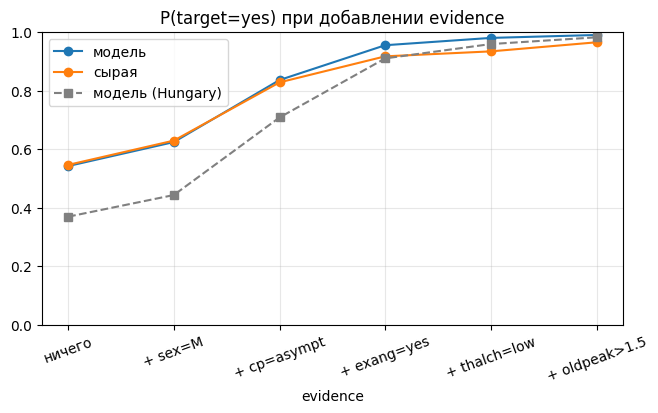

In [24]:
def emp(ev):                                   
    g = df
    for k, v in ev.items(): g = g[g[k] == v]
    return len(g), round(float((g.target == 'yes').mean()), 3)

base = [('ничего', {}), ('+ sex=M', {'sex': 'M'}), ('+ cp=asympt', {'sex': 'M', 'cp': 'asympt'}),
        ('+ exang=yes', {'sex': 'M', 'cp': 'asympt', 'exang': 'yes'}),
        ('+ thalch=low', {'sex': 'M', 'cp': 'asympt', 'exang': 'yes', 'thalch': 'low'}),
        ('+ oldpeak>1.5', {'sex': 'M', 'cp': 'asympt', 'exang': 'yes', 'thalch': 'low', 'oldpeak': '>1.5'})]
rows = []
for name, ev in base:
    ev_h = {**ev, 'dataset': 'Hungary'}
    rows.append((name, q('target', ev)['yes'], *emp(ev)[::-1], q('target', ev_h)['yes'], *emp(ev_h)[::-1]))
tab = pd.DataFrame(rows, columns=['evidence', 'модель', 'сырая', 'n', 'модель (Hungary)', 'сырая (Hungary)', 'n (Hungary)']).set_index('evidence')
print(tab.to_string())

ax = tab[['модель', 'сырая']].plot(marker='o', figsize=(7.5, 3.8), ylim=(0, 1), title='P(target=yes) при добавлении evidence')
tab['модель (Hungary)'].plot(marker='s', ls='--', ax=ax, color='gray'); ax.legend()
plt.xticks(rotation=20); plt.grid(alpha=.3); plt.show()

**Объяснение через структуру сети.**
* `sex` — родитель `target`: даёт умеренный сдвиг (+0.08). `cp`, `exang`, `thalch`, `oldpeak` — **потомки** `target`: их наблюдение работает как обратный вывод по формуле Байеса. Так как при известном диагнозе потомки почти независимы, их вклады перемножаются, и вероятность быстро растёт (скачки +0.21 от `cp`, +0.12 от `exang`, +0.03 и +0.01 далее).
* **Сеть завышает уверенность на последних шагах:** при четырёх признаках модель даёт 0.980 против сырых 0.934, при пяти — 0.990 против 0.965. Причина: потомки зависят друг от друга не только через диагноз, а в графе эти рёбра не проведены, так что подтверждающие признаки засчитываются как независимые.
* Начальное различие между клиниками (0.542 и 0.369) **сглаживается**: после пяти признаков 0.990 и 0.982. Сильное evidence про симптомы «вытесняет» априорную вероятность клиники; клиника важна, когда информации мало.

### Анализ структуры 

#### Удаление ребра

In [30]:
model_A = build([e for e in edges if e != ('dataset', 'target')])
infer_A = VariableElimination(model_A)
print('A: dataset -> target удалено      с ребром | без ребра | сырая доля (n)')
for ev in [{'dataset': 'Switzerland'}, {'dataset': 'Hungary'}, {'sex': 'M', 'age': '>60'}, {'exang': 'yes'},
           {'dataset': 'Switzerland', 'exang': 'yes'}, {'dataset': 'Hungary', 'exang': 'yes'}]:
    print(f'  {str(ev):52s}', q('target', ev)['yes'], '|', q('target', ev, infer_A)['yes'], '|', emp(ev)[::-1])

model_B = build([e for e in edges if e != ('exang', 'oldpeak')])
infer_B = VariableElimination(model_B)
ev = {'exang': 'yes', 'oldpeak': '>1.5'}
print('\nB: exang -> oldpeak удалено')
print('  P(target=yes | exang=yes, oldpeak>1.5):', q('target', ev)['yes'], '->', q('target', ev, infer_B)['yes'], '| сырая:', emp(ev)[::-1])
print('  P(oldpeak>1.5 | exang=yes):            ', q('oldpeak', {'exang': 'yes'})['>1.5'], '->', q('oldpeak', {'exang': 'yes'}, infer_B)['>1.5'])
print('  P(target=yes | exang=yes):             ', q('target', {'exang': 'yes'})['yes'], '->', q('target', {'exang': 'yes'}, infer_B)['yes'])

A: dataset -> target удалено      с ребром | без ребра | сырая доля (n)
  {'dataset': 'Switzerland'}                           0.89 | 0.63 | (0.932, 117)
  {'dataset': 'Hungary'}                               0.369 | 0.461 | (0.363, 292)
  {'sex': 'M', 'age': '>60'}                           0.803 | 0.819 | (0.823, 147)
  {'exang': 'yes'}                                     0.831 | 0.833 | (0.835, 333)
  {'dataset': 'Switzerland', 'exang': 'yes'}           0.971 | 0.876 | (0.98, 51)
  {'dataset': 'Hungary', 'exang': 'yes'}               0.708 | 0.78 | (0.787, 89)

B: exang -> oldpeak удалено
  P(target=yes | exang=yes, oldpeak>1.5): 0.926 -> 0.949 | сырая: (0.933, 135)
  P(oldpeak>1.5 | exang=yes):             0.395 -> 0.324
  P(target=yes | exang=yes):              0.831 -> 0.831


* **Результат изменился сильно там, где участвует клиника:** без ребра `dataset → target` сеть «узнаёт» о клинике лишь косвенно, через возраст, пол и пульс, и оценки для Switzerland падают с 0.890 до 0.630 (сырая 0.932), а для Hungary растут с 0.369 до 0.461. Запросы без клиники (`M >60`, `exang`) почти не меняются (разница ≤0.02): путь через удалённое ребро в них не участвует.
* **Не все оценки с ребром лучше:** для `Hungary, exang=yes` модель с ребром даёт 0.708 при сырой 0.787, а без ребра 0.780. Возможная причина — не включённые в граф рёбра `dataset → exang/cp`, но это предположение, которое я не проверял.

**(B) Удаляем `exang → oldpeak`.** `P(target=yes | exang=yes, oldpeak>1.5)` растёт с 0.926 до 0.949 (сырая 0.933), `P(oldpeak>1.5 | exang=yes)` падает с 0.395 до 0.324, а `P(target | exang=yes)` не меняется (0.831): `oldpeak` — лист, и без наблюдения по нему он не влияет. Без ребра сеть считает `exang` и `oldpeak` двумя независимыми свидетельствами и **дважды засчитывает общую информацию**, поэтому вывод завышен; с ребром он ближе к сырой доле.

### Причинность

**Построенную сеть нельзя считать причинной моделью.**
* **Обоснованно причинные:** `age → thalch` (старение снижает максимальный пульс), `age/sex → target` по направлению (возраст и пол — внешние признаки; но «причина» тут — маркер биологии и образа жизни, прямого эффекта не разделить).
* **Условно:** `target → cp/exang/oldpeak/thalch` — болезнь вызывает симптомы, но `target` — диагноз врача, поставленный в том числе по этим тестам, и по сути стрелка частично диагностическая. Высокую долю больных при `cp=asympt` нельзя читать как «отсутствие боли вызывает болезнь»: вероятно, это эффект отбора пациентов.
* **`dataset` не причина, а контекст:** клиника — по сути набор правил направления и протоколов измерений. Нельзя сказать «если перевести пациента в другую клинику, вероятность изменится»; различия в Switzerland (доля больных 93%) отражают, скорее, как отбирали пациентов.
* **`exang → oldpeak`** — условное направление (оба — следы нагрузочной ишемии).
* **Проблемы данных:** наблюдательная выборка из четырёх разных источников, пропуски, привязанные к клиникам и не случайные (удалены пациенты без нагрузочной пробы, что искажает долю больных), исключённые сильные признаки (`ca`, `thal`), неучтённые конфаундеры (лекарства, курение, диабет), малое число пациентов в части ячеек.

## Итог
* **Что удалось узнать.** Вероятность болезни сильно зависит от симптомов и демографии: `exang=yes` повышает её с 0.54 до 0.83, `cp=asympt` — до 0.78, `cp=atypical` снижает до 0.14; пожилой мужчина — 0.80, молодая женщина — 0.15. Оценки сети хорошо согласуются с сырыми долями в крупных группах.
* **Самые интересные зависимости.** (1) **Клиника-источник**: при одинаковых возрасте и поле вероятность болезни может различаться почти вдвое (Hungary 0.48, Switzerland 0.91), клиники отличаются и по пульсу/`oldpeak` при одинаковом диагнозе; (2) необычное поведение `cp`: «нет боли» — самый сильный признак болезни; (3) возраст и диагноз независимо снижают пульс.
* **Как evidence влияет на вероятности.** Признаки-следствия накапливаются (0.542 → 0.990 за пять шагов), прирост убывает; клиника важна лишь на старте (0.542 против 0.369), сильное evidence её «вытесняет». Модель на последних шагах **переоценивает** уверенность (0.980 против сырых 0.934).
* **Зависимость от структуры.** Удаление `dataset → target` сильно меняет оценки для клиник (Switzerland 0.890 → 0.630), удаление `exang → oldpeak` — небольшая двойная засчитанность (0.926 → 0.949); запросы без затронутых узлов не меняются; направление рёбер по данным не определить (эквивалентные графы).
* **Ограничения.** N = 857 после удаления 63 неполных строк (не случайных, в основном VA); исключены `chol`, `ca`, `thal`, `slope` из-за пропусков, привязанных к клиникам (потеря сильных предикторов); дискретизация; разреженные CPT (VA/Switzerland, женщины; ячейка с нулём пациентов даёт 0.50 из-за сглаживания); не включены остаточные рёбра (`cp–exang`, `dataset–cp` и др.) — это завышает уверенность; сеть не причинная.